Measures how much the charging network is used, how long chargers sit idle, where load peaks, and which stations or chargers are bottlenecks or underused, to support infrastructure decisions.  
Definitions used throughout:  

* **Utilisation:** share of a charger's available time that it is in use.
* **Idle time:** the rest of that time.
* **Load:** average power drawn (kW), found by spreading each session's energy evenly across its duration.
* **Capacity Factor:** energy delivered divided by the most the charger could deliver at its rated power.
* **Power ratio:** a session's average charging power divided by the charger's rated power.

**Set up**  
Libraries are imported, and the input path is set. show() saves every chart as a PNG in a figures folder (for the repo) and then displays it.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 50, 'axes.titlesize': 12, 'axes.labelsize': 10})

DATA_PATH = '/kaggle/input/datasets/sanyazuberi/ev-charging-raw-dataset/Copy of ev_charging_dataset.xlsx'
OUT = '/kaggle/working'
FIG_DIR = f'{OUT}/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def show(name):
    """Save the current figure as a PNG (for the repo) and display it."""
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=100, bbox_inches='tight')
    plt.show()

**Loading the data**  
All three sheets are loaded from the raw workbook: stations, chargers, and sessions. Unlike Tasks 1 and 2, utilisation needs the chargers table (rated power, station) as well as the sessions.

In [2]:
stations = pd.read_excel(DATA_PATH, sheet_name='stations')
chargers = pd.read_excel(DATA_PATH, sheet_name='chargers')
sessions = pd.read_excel(DATA_PATH, sheet_name='sessions')

print(f"stations: {len(stations)} | chargers: {len(chargers)} | sessions: {len(sessions):,}")

stations: 33 | chargers: 199 | sessions: 294,024


The network has 33 stations, 199 chargers, and 294,024 sessions.

**Checking that the tables are consistent**  
Before measuring anything, the tables were checked against each other: station and charger counts, whether every session belongs to a known charger, and how stations and charger types are distributed.

In [3]:
print('Station count matches unique station ids:', stations['station_id'].nunique() == len(stations))
print('n_chargers in the stations table adds up to the charger table:', stations['n_chargers'].sum() == len(chargers))
print('Every session belongs to a known charger:', sessions['charger_id'].isin(chargers['charger_id']).all())
print('Stations activated per year:', stations['activation_year'].value_counts().sort_index().to_dict())
print('Charger types:', chargers['charger_type'].value_counts().to_dict())
print('Chargers per station:', stations['n_chargers'].value_counts().sort_index().to_dict())

Station count matches unique station ids: True
n_chargers in the stations table adds up to the charger table: True
Every session belongs to a known charger: True
Stations activated per year: {2022: 8, 2023: 9, 2024: 16}
Charger types: {'DC_50kW': 95, 'DC_150kW': 69, 'DC_300kW': 35}
Chargers per station: {4: 9, 5: 6, 6: 4, 7: 3, 8: 11}


All checks passed. Stations were activated in 2022 (8), 2023 (9), and 2024 (16). There are 95 chargers rated 50 kW, 69 rated 150 kW, and 35 rated 300 kW. Stations have 4 chargers (9 stations), 5(6), 6(4), 7(3), or 8(11).

**Defining each charger's available time**  
Utilisation needs a denominator: how long each charger could have been used. I did not use installation_date because Task 1 found it inconsistent with actual session activity. Instead, each charger is treated as available from 1 January of its station's activation year until the end of 2024, and the check below tests that assumption.

In [4]:
END = pd.Timestamp('2025-01-01')   # the data ends at the end of 2024

# Each station is assumed to be available from 1 January of its activation year
stations['window_start'] = pd.to_datetime(stations['activation_year'].astype(str) + '-01-01')

chargers = chargers.merge(
    stations[['station_id', 'region', 'activation_year', 'window_start', 'n_chargers']], on='station_id')
chargers['window_min'] = (END - chargers['window_start']).dt.total_seconds() / 60
chargers['window_days'] = chargers['window_min'] / 1440

# Check the assumption: does each station's first session fall in its activation year?
activation = stations.set_index('station_id')['activation_year']
first_year = sessions.groupby('station_id')['start_timestamp'].min().dt.year.reindex(activation.index)
print('First session falls in the activation year for every station:', (first_year == activation).all())
print('Available hours per charger (min / max):',
      int(chargers['window_days'].min() * 24), '/', int(chargers['window_days'].max() * 24))

First session falls in the activation year for every station: True
Available hours per charger (min / max): 8784 / 26304


The first session at every station falls in its activation year, supporting the assumption. Available time ranges from 8,784 hours (stations activated in 2024) to 26,304 hours (2022).

**Data quantity: sessions that overlap on the same charger**  
A charger can only serve one vehicle at a time, so a session that starts before an earlier session on the same charger has finished is a data problem. This matters here because adding up session durations would count the overlapping time twice.

In [5]:
sessions = sessions.sort_values(['charger_id', 'start_timestamp']).reset_index(drop=True)

# A session "overlaps" if it starts before an earlier session on the same charger has finished
latest_end_before = sessions.groupby('charger_id')['end_timestamp'].transform(lambda x: x.cummax().shift())
sessions['overlaps_earlier_session'] = sessions['start_timestamp'] < latest_end_before

n_over = int(sessions['overlaps_earlier_session'].sum())
n_same_start = int(sessions.duplicated(['charger_id', 'start_timestamp']).sum())
print(f"Sessions overlapping an earlier session on the same charger: {n_over:,} ({n_over / len(sessions):.1%})")
print(f"Sessions starting at the exact same moment as another on the same charger: {n_same_start:,}")

sessions['start_hour'] = sessions['start_timestamp'].dt.hour
overlap_by_type = sessions.groupby('charger_type')['overlaps_earlier_session'].mean().round(3)
overlap_by_hour = sessions.groupby('start_hour')['overlaps_earlier_session'].mean()
print('\nOverlap rate by charger type:', overlap_by_type.to_dict())
print(f"Overlap rate overnight (00-05h): {overlap_by_hour.loc[0:5].mean():.1%} | midday (10-14h): {overlap_by_hour.loc[10:14].mean():.1%}")

Sessions overlapping an earlier session on the same charger: 24,449 (8.3%)
Sessions starting at the exact same moment as another on the same charger: 3,808

Overlap rate by charger type: {'DC_150kW': 0.06, 'DC_300kW': 0.046, 'DC_50kW': 0.116}
Overlap rate overnight (00-05h): 1.2% | midday (10-14h): 11.0%


24,449 sessions (8.3%) overlap an earlier session on the same charger, and 3,808 start at the exact same moment as another session on that charger. The overlap rate is 1.2% overnight but 11.0% at midday, and highest on 50 kW chargers (11.6%, against 6.0% for 150 kW and 4.6% for 300 kW). That pattern suggests sessions were assigned to chargers without checking availability, so clashes are more likely when chargers are busy and sessions last longer.

**Merging overlaps into busy periods**  
To avoid counting overlapping time twice, sessions on the same charger that overlap or touch are merged into continuous busy periods. Utilisation is calculated from these merged periods. One session runs just past midnight on 31 December, so its end is clipped to the end of the data.

In [6]:
sessions['end_clipped'] = sessions['end_timestamp'].clip(upper=END)   # one session runs just past 31 Dec

def merge_intervals(df):
    """Merge overlapping sessions on the same charger into continuous busy periods."""
    start = df['start_timestamp'].values.astype('datetime64[s]').astype('int64')
    end = df['end_clipped'].values.astype('datetime64[s]').astype('int64')
    ids = df['charger_id'].values
    out = []
    cur_id, cur_s, cur_e = ids[0], start[0], end[0]
    for cid, s, e in zip(ids[1:], start[1:], end[1:]):
        if cid == cur_id and s <= cur_e:      # overlaps or touches the current busy period
            cur_e = max(cur_e, e)
        else:
            out.append((cur_id, cur_s, cur_e))
            cur_id, cur_s, cur_e = cid, s, e
    out.append((cur_id, cur_s, cur_e))
    res = pd.DataFrame(out, columns=['charger_id', 'start', 'end'])
    res['start'] = pd.to_datetime(res['start'], unit='s')
    res['end'] = pd.to_datetime(res['end'], unit='s')
    res['minutes'] = (res['end'] - res['start']).dt.total_seconds() / 60
    return res

iv = merge_intervals(sessions)
iv['station_id'] = iv['charger_id'].map(chargers.set_index('charger_id')['station_id'])

naive_min = sessions['session_duration_minutes'].sum()
union_min = iv['minutes'].sum()
print(f"{len(sessions):,} sessions merge into {len(iv):,} busy periods")
print(f"Summed session minutes: {naive_min:,.0f} | actual busy minutes: {union_min:,.0f}")
print(f"Summing durations would overstate busy time by {(naive_min - union_min) / union_min:.1%}")

294,024 sessions merge into 268,857 busy periods
Summed session minutes: 10,318,702 | actual busy minutes: 9,804,122
Summing durations would overstate busy time by 5.2%


The 294,024 sessions merge into 268,857 busy periods. Summing session durations gives 10.32 million minutes against 9.80 million minutes of actual busy time, so a naive calculation would overstate usage by 5.2%.

**Were the double-booked sessions caused by a shortage of chargers?**  
If double-booked sessions happened because a station was full, that would point to a capacity shortage. For each overlapping session, this checks whether at least one charger at the same station was free at that moment.

In [7]:
n_chargers = stations.set_index('station_id')['n_chargers']

def active_chargers_at(times, station_iv):
    """How many chargers at a station are busy at each given time?"""
    s = np.sort(station_iv['start'].values.astype('datetime64[s]').astype('int64'))
    e = np.sort(station_iv['end'].values.astype('datetime64[s]').astype('int64'))
    t = times.values.astype('datetime64[s]').astype('int64')
    return np.searchsorted(s, t, side='right') - np.searchsorted(e, t, side='right')

overlapping = sessions[sessions['overlaps_earlier_session']]
had_free = []
for sid, g in overlapping.groupby('station_id'):
    busy_now = active_chargers_at(g['start_timestamp'], iv[iv['station_id'] == sid])
    had_free.append(pd.Series(n_chargers[sid] - busy_now >= 1, index=g.index))
had_free = pd.concat(had_free)
print(f"Double-booked sessions where another charger at the same station was free: {had_free.mean():.1%}")

Double-booked sessions where another charger at the same station was free: 99.8%


In 99.8% of cases, another charger at the same station was free. Therefore, the double-booking does not reflect a shortage of capacity. It looks like a charger-allocation artefact, so we treat overlaps as a data-quality issue, not evidence of congestion.

**Building the charger-level table**  
One row per charger, with its busy time, utilisation, and daily output. Alongside utilisation, two efficiency measures are added: the power ratio (how close sessions get to the charger's rated power) and the capacity factor (energy delivered versus the maximum possible).

In [8]:
ch = chargers.set_index('charger_id').copy()
ch['busy_min'] = iv.groupby('charger_id')['minutes'].sum()
ch['utilisation'] = ch['busy_min'] / ch['window_min']

by_charger = sessions.groupby('charger_id')
ch['sessions'] = by_charger.size()
ch['energy_kwh'] = by_charger['energy_kwh'].sum()
ch['revenue'] = by_charger['total_cost'].sum()
ch['sessions_per_day'] = ch['sessions'] / ch['window_days']
ch['kwh_per_day'] = ch['energy_kwh'] / ch['window_days']
ch['revenue_per_day'] = ch['revenue'] / ch['window_days']

# Efficiency: average charging power during sessions vs the charger's rated power
sessions['avg_kw'] = sessions['energy_kwh'] / (sessions['session_duration_minutes'] / 60)
sessions['rated_kw'] = sessions['charger_id'].map(ch['max_power_kW'])
ch['power_ratio'] = (sessions['avg_kw'] / sessions['rated_kw']).groupby(sessions['charger_id']).mean()

# Capacity factor: energy delivered vs the most the charger could have delivered
ch['capacity_factor'] = ch['energy_kwh'] / (ch['max_power_kW'] * ch['window_days'] * 24)

network_util = ch['busy_min'].sum() / ch['window_min'].sum()
print(f"Network utilisation (share of available time a charger is in use): {network_util:.2%}")
print(f"Average idle time per charger per day: {24 * (1 - network_util):.1f} of 24 hours")
print(ch['utilisation'].describe().round(4))

Network utilisation (share of available time a charger is in use): 5.41%
Average idle time per charger per day: 22.7 of 24 hours
count    199.0000
mean       0.0538
std        0.0254
min        0.0215
25%        0.0325
50%        0.0540
75%        0.0608
max        0.1154
Name: utilisation, dtype: float64


Network utilisation is 5.41%: the average charger sits idle for 22.7 of every 24 hours. Individual chargers range from 2.2% to 11.5% utilisation, with a median of 5.4%.

**What drives differences in utilisation?**  
I compared utilisation by charger type and by the number of chargers at the station. The session-per-day figures show how demand is shared out.

              chargers  utilisation
charger_type                       
DC_150kW            69       0.0365
DC_300kW            35       0.0324
DC_50kW             95       0.0743

            chargers  utilisation  sessions_per_day
n_chargers                                         
4                 36       0.0850            3.4604
5                 30       0.0545            2.7943
6                 24       0.0570            2.3249
7                 21       0.0446            1.9946
8                 88       0.0422            1.7208

Sessions per station per day, by number of chargers at the station:
{4: 13.84, 5: 13.97, 6: 13.95, 7: 13.96, 8: 13.77}


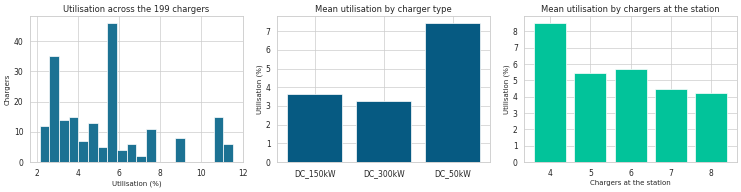

In [9]:
by_type = ch.groupby('charger_type').agg(chargers=('busy_min', 'size'), utilisation=('utilisation', 'mean'))
by_size = ch.groupby('n_chargers').agg(chargers=('busy_min', 'size'), utilisation=('utilisation', 'mean'),
                                       sessions_per_day=('sessions_per_day', 'mean'))
print(by_type.round(4)); print(); print(by_size.round(4))

station_day = sessions.groupby('station_id').size() / stations.set_index('station_id')['window_start'].rsub(END).dt.days
print('\nSessions per station per day, by number of chargers at the station:')
print(station_day.groupby(n_chargers).mean().round(2).to_dict())

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(ch['utilisation'] * 100, bins=20, color='#1C7293')
ax[0].set(title='Utilisation across the 199 chargers', xlabel='Utilisation (%)', ylabel='Chargers')
ax[1].bar(by_type.index, by_type['utilisation'] * 100, color='#065A82')
ax[1].set(title='Mean utilisation by charger type', ylabel='Utilisation (%)')
ax[2].bar(by_size.index.astype(str), by_size['utilisation'] * 100, color='#02C39A')
ax[2].set(title='Mean utilisation by chargers at the station', xlabel='Chargers at the station', ylabel='Utilisation (%)')
show('01_utilisation_overview')

* **Every station receives about 13.9 sessions per day, whatever its size** (13.84 at 4-charger stations, 13.77 at 8-charger stations). So utilisation falls as stations get bigger: 8.5% at 4-charger stations, 5.5% at 5, 5.7% at 6, 4.5% at 7, and 4.2% at 8. Sessions per charger-day fall from 3.46 to 1.72.
* **Charger type matters too:** 50kW chargers average 7.4% utilisation, 150 kW chargers 3.7%, and 300 kW chargers 3.2%. Within stations, every type gets the same number of sessions per day, so the difference comes from session length: slower chargers are occupied for longer per session.

**Preparing hourly data for the heatmaps**  
To see when chargers are used, I cut each busy period at clock-hour boundaries so every piece falls within one hour. The code also counts how many of each weekday fall inside each charger's available window, which is needed to turn busy minutes into a percentage. 

In [10]:
def split_by_hour(start, end):
    """Cut each interval at clock-hour boundaries so every piece sits inside one hour.
    Returns the row number each piece came from, the hour it falls in, and its length in minutes."""
    start = start.values.astype('datetime64[s]')
    end = end.values.astype('datetime64[s]')
    idx, cur = np.arange(len(start)), start.copy()
    rows, hours, mins = [], [], []
    while len(idx):
        hour_start = cur.astype('datetime64[h]').astype('datetime64[s]')
        seg_end = np.minimum(hour_start + np.timedelta64(1, 'h'), end[idx])
        rows.append(idx); hours.append(hour_start); mins.append((seg_end - cur) / np.timedelta64(1, 'm'))
        keep = seg_end < end[idx]
        idx, cur = idx[keep], seg_end[keep]
    return np.concatenate(rows), np.concatenate(hours), np.concatenate(mins)

rows, hours, mins = split_by_hour(iv['start'], iv['end'])
busy_pieces = pd.DataFrame({
    'charger_id': iv['charger_id'].values[rows],
    'hour_start': pd.to_datetime(hours),
    'busy_min': mins})
busy_pieces['station_id'] = busy_pieces['charger_id'].map(chargers.set_index('charger_id')['station_id'])
busy_pieces['hour'] = busy_pieces['hour_start'].dt.hour
busy_pieces['weekday'] = busy_pieces['hour_start'].dt.dayofweek

# How many of each weekday fall inside each charger's available window?
def weekday_counts(window_start):
    d = pd.date_range(window_start, END, freq='D', inclusive='left')
    return pd.Series(d.dayofweek).value_counts().reindex(range(7), fill_value=0)

wd_days_by_window = {ws: weekday_counts(ws) for ws in ch['window_start'].unique()}
charger_weekday_days = pd.DataFrame({cid: wd_days_by_window[ws] for cid, ws in ch['window_start'].items()}).T
print(f"{len(iv):,} busy periods split into {len(busy_pieces):,} hourly pieces")

268,857 busy periods split into 407,426 hourly pieces


The 268,857 busy periods are split into 407,426 hourly pieces.

**Utilisation heatmap: whole network**  
Share of time the charger is in use for each weekday and hour of the day.

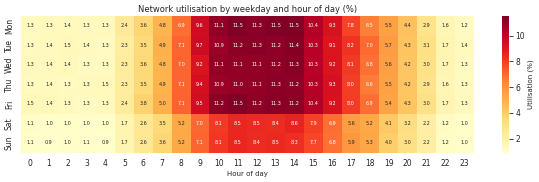

Busiest cell: ('Mon', np.int32(11)) at 11.5%
Weekday midday (Mon-Fri, 10-14h) average: 11.2%
Weekend midday (Sat-Sun, 10-14h) average: 8.4%
Overnight (00-04h) average: 1.2%


In [11]:
# Share of time chargers are in use, for each weekday and hour of the day (whole network)
busy = busy_pieces.groupby(['weekday', 'hour'])['busy_min'].sum().unstack()
available = charger_weekday_days.sum() * 60          # available minutes per hour-slot, per weekday
heat_network = busy.div(available, axis=0) * 100
heat_network.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

plt.figure(figsize=(12, 3.8))
sns.heatmap(heat_network, cmap='YlOrRd', annot=True, fmt='.1f', annot_kws={'size': 7},
            cbar_kws={'label': 'Utilisation (%)'})
plt.title('Network utilisation by weekday and hour of day (%)')
plt.xlabel('Hour of day'); plt.ylabel('')
show('02_heatmap_network_weekday_hour')

print(f"Busiest cell: {heat_network.stack().idxmax()} at {heat_network.stack().max():.1f}%")
print(f"Weekday midday (Mon-Fri, 10-14h) average: {heat_network.loc['Mon':'Fri', 10:14].values.mean():.1f}%")
print(f"Weekend midday (Sat-Sun, 10-14h) average: {heat_network.loc['Sat':'Sun', 10:14].values.mean():.1f}%")
print(f"Overnight (00-04h) average: {heat_network.loc[:, 0:4].values.mean():.1f}%")

Use is concentrated between 09:00 and 15:00. The busiest hour is Monday at 11:00, with 11.5% utilisation. Weekday midday (10:00-14:59) averages 11.2%, and weekend midday is 8.4%, while overnight (00:00-04:59) is 1.2%. Each of the week's busiest hours leaves chargers idle nearly 90% of the time.

**Utilisation heatmap: per station**  
One row per station, one column per hour of the day, ordered from the most to the least utilised station. The label shows how many chargers each station has.

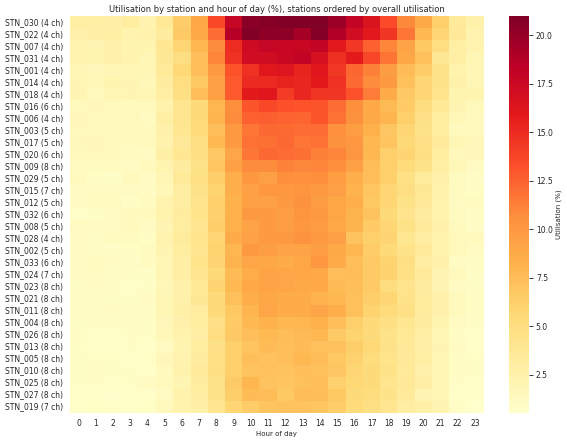

In [12]:
# Share of time chargers are in use, for each station and hour of the day
busy_sh = busy_pieces.groupby(['station_id', 'hour'])['busy_min'].sum().unstack().reindex(columns=range(24), fill_value=0)
avail_station = ch.groupby('station_id')['window_days'].sum() * 60
heat_station = busy_sh.div(avail_station, axis=0) * 100

order = ch.groupby('station_id')['utilisation'].mean().sort_values(ascending=False).index
heat_station = heat_station.loc[order]
labels = [f"{s} ({n_chargers[s]} ch)" for s in heat_station.index]

plt.figure(figsize=(12, 9))
sns.heatmap(heat_station, cmap='YlOrRd', yticklabels=labels, cbar_kws={'label': 'Utilisation (%)'})
plt.title('Utilisation by station and hour of day (%), stations ordered by overall utilisation')
plt.xlabel('Hour of day'); plt.ylabel('')
show('03_heatmap_station_hour')

Every station follows the same daily shape, with a midday plateau and a quiet night. The top of the chart shows the 4-charger stations, and utilisation fades steadily toward the 8-charger stations at the bottom. Stations differ in how bright the midday band is, not in when it happens.

**Utilisation heatmap: per charger**  
The same view for each of the 199 chargers, grouped by station. This chart is tall because it has one row per charger.

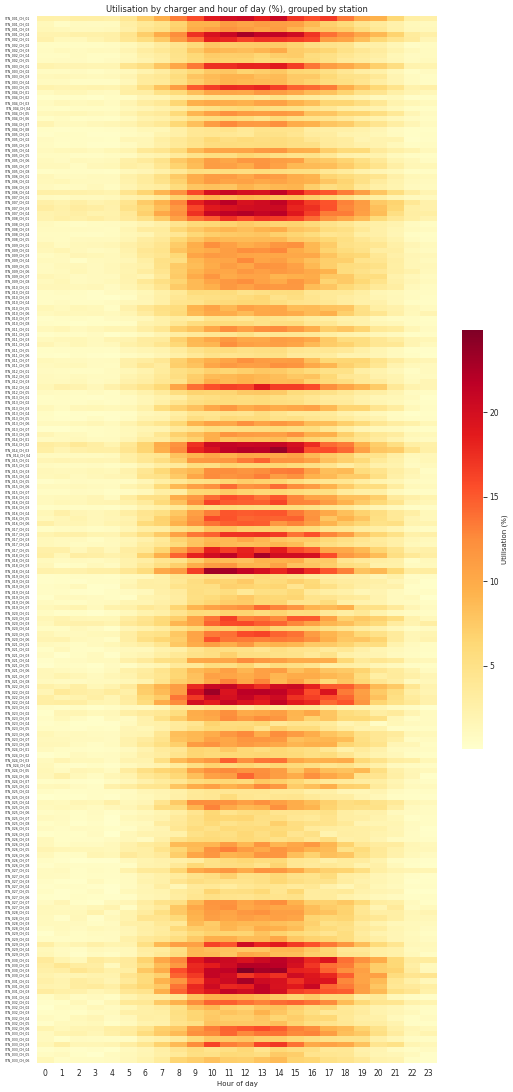

In [13]:
busy_ch = busy_pieces.groupby(['charger_id', 'hour'])['busy_min'].sum().unstack().reindex(columns=range(24), fill_value=0)
heat_charger = busy_ch.div(ch['window_days'] * 60, axis=0).reindex(ch.index) * 100

plt.figure(figsize=(11, 22))
sns.heatmap(heat_charger, cmap='YlOrRd', yticklabels=True, cbar_kws={'label': 'Utilisation (%)', 'shrink': 0.4})
plt.yticks(fontsize=4.5)
plt.title('Utilisation by charger and hour of day (%), grouped by station')
plt.xlabel('Hour of day'); plt.ylabel('')
show('04_heatmap_charger_hour')

Chargers within the same station look alike; the differences seen are between stations and between charger types. The ranking section below tests whether any individual charger really stands out.

**Utilisation heatmap: weekday and hour for one station**   
A reusable function that draws the weekday-by-hour heatmap for any station. It shows the busiest station; the commented line shows how to view another one.

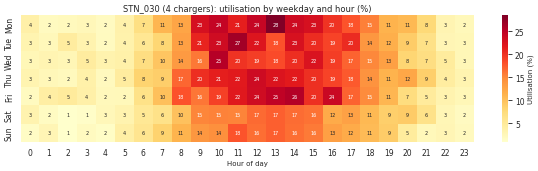

In [14]:
def station_heatmap(station_id):
    """Weekday x hour utilisation heatmap for any single station."""
    ids = ch.index[ch['station_id'] == station_id]
    b = busy_pieces[busy_pieces['station_id'] == station_id].groupby(['weekday', 'hour'])['busy_min'].sum().unstack()
    b = b.reindex(index=range(7), columns=range(24), fill_value=0)
    h = b.div(charger_weekday_days.loc[ids].sum() * 60, axis=0) * 100
    h.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
    plt.figure(figsize=(12, 3.6))
    sns.heatmap(h, cmap='YlOrRd', annot=True, fmt='.0f', annot_kws={'size': 7}, cbar_kws={'label': 'Utilisation (%)'})
    plt.title(f'{station_id} ({len(ids)} chargers): utilisation by weekday and hour (%)')
    plt.xlabel('Hour of day'); plt.ylabel('')

busiest_station = order[0]
station_heatmap(busiest_station)
show('05_heatmap_busiest_station')
# station_heatmap('STN_010')   # change the id to look at any other station

The busiest station is STN_030 (London, 4 chargers). Its weekday midday cells reach roughly 20% utilisation, about double the network average but still far from full.

**Idle-time analysis: how long chargers sit idle**  
Idle time is whatever is left after busy time. The gaps between consecutive busy periods show how long a charger waits between uses, and the hourly view shows when chargers are idle.

In [15]:
iv = iv.sort_values(['charger_id', 'start']).reset_index(drop=True)
iv['idle_before_min'] = (iv['start'] - iv.groupby('charger_id')['end'].shift()).dt.total_seconds() / 60
gaps = iv['idle_before_min'].dropna()

print(f"Idle share of available time (network): {1 - network_util:.1%}")
print(f"Gaps between busy periods: {len(gaps):,}")
print(f"Median gap: {gaps.median() / 60:.1f} h | mean: {gaps.mean() / 60:.1f} h")
print(f"90th percentile: {gaps.quantile(0.9) / 60:.1f} h | 99th percentile: {gaps.quantile(0.99) / 60:.1f} h | longest: {gaps.max() / 1440:.1f} days")

idle_by_hour = 100 - heat_network.mean()          # simple average over the 7 weekdays
print(f"\nIdle share overnight (00-04h): {idle_by_hour.loc[0:4].mean():.1f}% | midday (10-14h): {idle_by_hour.loc[10:14].mean():.1f}%")

Idle share of available time (network): 94.6%
Gaps between busy periods: 268,658
Median gap: 6.1 h | mean: 10.6 h
90th percentile: 24.0 h | 99th percentile: 51.3 h | longest: 8.2 days

Idle share overnight (00-04h): 98.8% | midday (10-14h): 89.6%


Chargers are idle 94.6% of the time. The median wait between uses is 6.1 hours (mean 10.6). 90% of gaps are under 24 hours, 99% are under 51.3 hours, and the longest is 8.2 days. Idle share is 98.8% overnight and 89.6% at midday.

**Idle-time charts**  
The left chart shows how long chargers wait between uses (capped at 48 hours so the main shape is visible). The right chart shows the idle share by hour of the day.

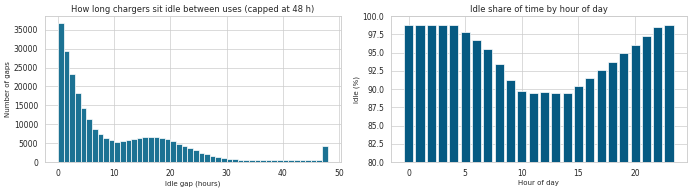

Average idle hours per day by charger type: {'DC_150kW': 23.1, 'DC_300kW': 23.2, 'DC_50kW': 22.2}

Chargers with the longest single idle spell (days):
charger_id
STN_025_CH_02    8.2
STN_004_CH_02    8.1
STN_004_CH_05    7.2
STN_010_CH_07    5.9
STN_009_CH_03    5.8


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(gaps.clip(upper=2880) / 60, bins=48, color='#1C7293')
ax[0].set(title='How long chargers sit idle between uses (capped at 48 h)', xlabel='Idle gap (hours)', ylabel='Number of gaps')
ax[1].bar(idle_by_hour.index, idle_by_hour.values, color='#065A82')
ax[1].set_ylim(80, 100)
ax[1].set(title='Idle share of time by hour of day', xlabel='Hour of day', ylabel='Idle (%)')
show('06_idle_time')

idle_summary = ch.assign(idle_h_per_day=24 * (1 - ch['utilisation'])).groupby('charger_type')['idle_h_per_day'].mean().round(1)
longest = iv.groupby('charger_id')['idle_before_min'].max().div(1440).sort_values(ascending=False)
print('Average idle hours per day by charger type:', idle_summary.to_dict())
print('\nChargers with the longest single idle spell (days):')
print(longest.head(5).round(1).to_string())

Gaps cluster at a few hours, with a long tail. Idle hours per day are 22.2 for 50 kW chargers, 23.1 for 150 kW, and 23.2 for 300 kW. The longest single idle spells are on STN_025_CH_02 (8.2 days), STN_004_CH_02 (8.1 days), and STN_004_CH_05 (7.2 days). The data contains no fault or downtime records, so it cannot show whether these long gaps are outages or just a quiet run.

**Peak-load analysis: how much power the network draws**  
I measure load in kW by spreading each session's energy evenly over the hours it spans. This uses 2024 only because all 33 stations were active that year, and compares the result with the installed capacity (the sum of every charger's rated power).

In [17]:
rows, hours, mins = split_by_hour(sessions['start_timestamp'], sessions['end_timestamp'])
load = pd.DataFrame({
    'hour_start': pd.to_datetime(hours),
    'station_id': sessions['station_id'].values[rows],
    'kwh': sessions['energy_kwh'].values[rows] * mins / sessions['session_duration_minutes'].values[rows]})
load = load[load['hour_start'].dt.year == 2024]      # 2024: all 33 stations are active

hours_2024 = pd.date_range('2024-01-01', '2024-12-31 23:00', freq='h')
net_kw = load.groupby('hour_start')['kwh'].sum().reindex(hours_2024, fill_value=0)   # kWh in an hour = average kW
net = pd.DataFrame({'kw': net_kw.values, 'hour': hours_2024.hour, 'weekend': hours_2024.dayofweek >= 5})
profile = net.groupby(['weekend', 'hour'])['kw'].mean().unstack(0)
profile.columns = ['Weekday', 'Weekend']

installed_kw = ch['max_power_kW'].sum()
print(f"Installed charging capacity: {installed_kw:,} kW across {len(ch)} chargers")
print(f"Average load through 2024: {net['kw'].mean():,.0f} kW ({net['kw'].mean() / installed_kw:.1%} of installed)")
print(f"Weekday peak hour: {profile['Weekday'].idxmax()}:00, average {profile['Weekday'].max():,.0f} kW ({profile['Weekday'].max() / installed_kw:.1%} of installed)")
print(f"Weekend peak hour: {profile['Weekend'].idxmax()}:00, average {profile['Weekend'].max():,.0f} kW")
print(f"Highest single hour in 2024: {net_kw.idxmax()}, {net_kw.max():,.0f} kW ({net_kw.max() / installed_kw:.1%} of installed)")

Installed charging capacity: 25,600 kW across 199 chargers
Average load through 2024: 882 kW (3.4% of installed)
Weekday peak hour: 13:00, average 1,882 kW (7.4% of installed)
Weekend peak hour: 11:00, average 1,397 kW
Highest single hour in 2024: 2024-01-29 14:00:00, 2,796 kW (10.9% of installed)


Installed capacity is 25,600kW. The network averages 882kW through 2024 (3.4% of installed). The weekday peak is at 13:00, averaging 1,882kW (7.4% of installed), and the weekend peak is at 11:00 (1,397kW). The highest single hour of 2024 was at 14:00 on 29 January at 2,796kW, which is 10.9% of installed capacity.

**Peak-load charts**  
The left chart shows average load by hour on weekdays and weekends, and the right shows the same as a share of installed capacity. The table finds each station's busiest hour relative to its own installed kW.

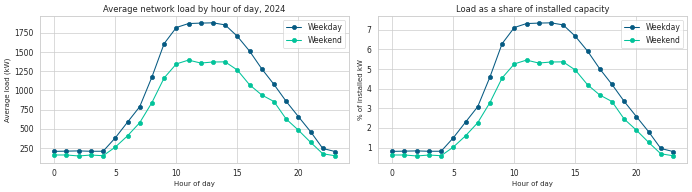

            peak_hour  peak_kw  installed_kw  peak_share_of_installed
station_id                                                           
STN_030            13   38.318           200                    0.192
STN_022            10   38.076           200                    0.190
STN_001            14   50.235           400                    0.126
STN_031            12   50.782           450                    0.113
STN_007            13   49.928           450                    0.111

Station peak load as a share of installed kW: median 7.4% | highest 19.2%


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
profile.plot(ax=ax[0], marker='o', color=['#065A82', '#02C39A'])
ax[0].set(title='Average network load by hour of day, 2024', xlabel='Hour of day', ylabel='Average load (kW)')
(profile / installed_kw * 100).plot(ax=ax[1], marker='o', color=['#065A82', '#02C39A'])
ax[1].set(title='Load as a share of installed capacity', xlabel='Hour of day', ylabel='% of installed kW')
show('07_peak_load')

# Station level: the busiest hour of the day at each station, relative to the station's installed kW
st_hour = load.groupby(['station_id', load['hour_start'].dt.hour])['kwh'].sum().unstack().reindex(columns=range(24), fill_value=0) / 366
st_kw = ch.groupby('station_id')['max_power_kW'].sum()
st_peak = pd.DataFrame({'peak_hour': st_hour.idxmax(axis=1), 'peak_kw': st_hour.max(axis=1), 'installed_kw': st_kw})
st_peak['peak_share_of_installed'] = st_peak['peak_kw'] / st_peak['installed_kw']
print(st_peak.sort_values('peak_share_of_installed', ascending=False).head(5).round(3).to_string())
print('\nStation peak load as a share of installed kW: median', f"{st_peak['peak_share_of_installed'].median():.1%}",
      '| highest', f"{st_peak['peak_share_of_installed'].max():.1%}")

Load follows the same shape as utilisation: a midday plateau, with the weekday curve above the weekend one. At station level, the highest peak is STN_030 at 13:00 (38 kW against 200 kW installed, 19.2%), followed by STN_022 (19.0%), STN_001 (12.6%), STN_031 (11.3%), and STN_007 (11.1%). The median station peaks at 7.4% of its installed power. No station comes close to its power limit. 

**Does the peak-price window match the load peak?**  
Task 2 found that prices carry a premium of about 10% between 16:00 and 20:59. This compares that window with the hours when most energy is delivered (2024).

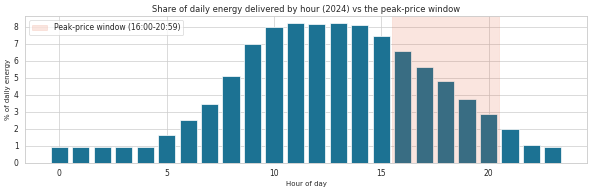

Energy delivered 10:00-14:59: 40.7% | 16:00-20:59 (peak-price window): 23.6%
Average price 16-20h: £0.632 | other hours: £0.575 per kWh


In [19]:
s24 = sessions[sessions['year'] == 2024]
price_by_hour = s24.groupby(s24['start_timestamp'].dt.hour)['price_per_kwh'].mean()
energy_share = load.groupby(load['hour_start'].dt.hour)['kwh'].sum()
energy_share = energy_share / energy_share.sum() * 100

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(energy_share.index, energy_share.values, color='#1C7293')
ax.axvspan(15.5, 20.5, color='#E4572E', alpha=0.15, label='Peak-price window (16:00-20:59)')
ax.set(title='Share of daily energy delivered by hour (2024) vs the peak-price window',
       xlabel='Hour of day', ylabel='% of daily energy')
ax.legend()
show('08_load_vs_price_window')

print(f"Energy delivered 10:00-14:59: {energy_share.loc[10:14].sum():.1f}% | 16:00-20:59 (peak-price window): {energy_share.loc[16:20].sum():.1f}%")
print(f"Average price 16-20h: £{price_by_hour.loc[16:20].mean():.3f} | other hours: £{price_by_hour.drop(range(16, 21)).mean():.3f} per kWh")

40.7% of daily energy is delivered between 10:00 and 14:59, but only 23.6% falls inside the 16:00-20:59 peak-price window. The premium (£0.632 against £0.575 per kWh) sits on the shoulder after the load peak, not on it. Task 2 found no detectable price response, so these results do not show that moving the window would shift demand.

**Station occupancy: how many chargers are busy at once?**  
For each station, this measures how much time is spent with 0, 1, 2,... chargers busy at the same time. It gives the share of time a station is nearly full, which directly measures the bottleneck.

In [20]:
def occupancy_minutes(g, n_ch, window_min):
    """Minutes the station spends with 0, 1, 2 ... n chargers busy at once."""
    ev = pd.concat([pd.DataFrame({'t': g['start'], 'd': 1}), pd.DataFrame({'t': g['end'], 'd': -1})]).sort_values('t', kind='stable')
    ev['occ'] = ev['d'].cumsum()
    ev['dur'] = (ev['t'].shift(-1) - ev['t']).dt.total_seconds() / 60
    ev = ev.iloc[:-1]
    mins = ev.groupby('occ')['dur'].sum().reindex(range(n_ch + 1), fill_value=0)
    mins.loc[0] += window_min - mins.sum()          # time outside the first/last event is idle too
    return mins

window_min_st = ch.groupby('station_id')['window_min'].first()
occ = {sid: occupancy_minutes(g, n_chargers[sid], window_min_st[sid]) for sid, g in iv.groupby('station_id')}

station = pd.DataFrame({
    'n_chargers': n_chargers,
    'region': stations.set_index('station_id')['region'],
    'utilisation': ch.groupby('station_id')['utilisation'].mean()})
station['peak_window_util'] = heat_station.loc[:, 10:14].mean(axis=1) / 100
station['pct_time_75pct_busy'] = [100 * occ[s].iloc[int(np.ceil(0.75 * n_chargers[s])):].sum() / window_min_st[s] for s in station.index]
station['pct_time_all_busy'] = [100 * occ[s].loc[n_chargers[s]] / window_min_st[s] for s in station.index]
station['max_busy_at_once'] = [int(occ[s][occ[s] > 0].index.max()) for s in station.index]

print(f"Stations that ever had every charger busy at the same time: {(station['pct_time_all_busy'] > 0).sum()} of {len(station)}")
print(f"Highest share of time with every charger busy: {station['pct_time_all_busy'].max():.3f}%")
print(station.groupby('n_chargers')[['utilisation', 'peak_window_util', 'pct_time_75pct_busy', 'pct_time_all_busy']].mean().round(4))

Stations that ever had every charger busy at the same time: 14 of 33
Highest share of time with every charger busy: 0.061%
            utilisation  peak_window_util  pct_time_75pct_busy  \
n_chargers                                                       
4                0.0850            0.1611               0.5513   
5                0.0545            0.1053               0.0126   
6                0.0570            0.1103               0.0018   
7                0.0446            0.0862               0.0000   
8                0.0422            0.0815               0.0002   

            pct_time_all_busy  
n_chargers                     
4                      0.0200  
5                      0.0004  
6                      0.0000  
7                      0.0000  
8                      0.0000  


Only 14 of 33 stations ever had every charger busy at the same time, and the highest share of time for any station is 0.061%. By station size, the average share of time with at least 75% of chargers busy is 0.55% at 4-charger stations, 0.031% at 5,0.002% at 6, and effectively zero at 7 and 8. Peak-window (10:00-14:59) utilisation averages 16.1% at 4-charger stations and 8.2% at 8-charger stations.

**Ranking stations by how close they get to full**  
Stations are ranked by the share of time when at least 75% of their chargers are busy, and the chart colours each bar by the number of chargers the station has.

            n_chargers      region  utilisation  peak_window_util  pct_time_75pct_busy  pct_time_all_busy  max_busy_at_once
station_id                                                                                                                 
STN_030              4      London        0.112             0.208                1.116              0.061                 4
STN_022              4      London        0.109             0.203                1.045              0.034                 4
STN_031              4    Midlands        0.092             0.174                0.633              0.017                 4
STN_007              4  North East        0.093             0.177                0.629              0.021                 4
STN_001              4  North West        0.083             0.157                0.403              0.011                 4
STN_018              4  South East        0.080             0.152                0.401              0.009                 4
STN_014 

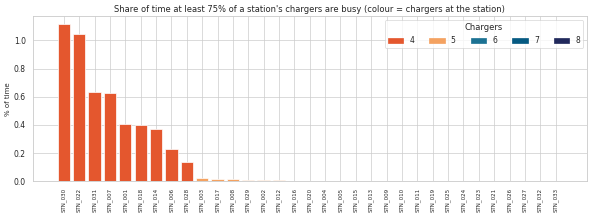

In [21]:
bott = station.sort_values('pct_time_75pct_busy', ascending=False)
print(bott.head(10).round(3).to_string())

plt.figure(figsize=(12, 4.5))
colours = bott['n_chargers'].map({4: '#E4572E', 5: '#F4A261', 6: '#1C7293', 7: '#065A82', 8: '#21295C'})
plt.bar(bott.index, bott['pct_time_75pct_busy'], color=colours)
plt.xticks(rotation=90, fontsize=8)
plt.title('Share of time at least 75% of a station\'s chargers are busy (colour = chargers at the station)')
plt.ylabel('% of time')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ['#E4572E', '#F4A261', '#1C7293', '#065A82', '#21295C']]
plt.legend(handles, ['4', '5', '6', '7', '8'], title='Chargers', ncol=5)
show('09_bottleneck_stations')

The nine most congested stations are exactly the nine 4-charger stations. STN_030 and STN_022 (both in London) are the highest: at least 75% of chargers are busy for 1.12% and 1.05% of the time, and every charger is busy for 0.051% and 0.034% of the time. Next come STN_031 (Midlands, 0.63%), STN_007 (North East, 0.63%), STN_001 (North West, 0.40%), and STN_018 (South East, 0.40%). Even the worst bottleneck is busy-to-capacity for about 5 hours a year, so these are stations to watch, not stations in difficulty.

**Ranking chargers by utilisation**  
All 199 chargers are ranked by utilisation, with the top and bottom 10 shown alongside their daily sessions, energy, revenue, and power ratio.

In [22]:
ch['rank_utilisation'] = ch['utilisation'].rank(ascending=False, method='min').astype(int)
cols = ['station_id', 'charger_type', 'n_chargers', 'utilisation', 'sessions_per_day', 'kwh_per_day', 'revenue_per_day', 'power_ratio']
ranked = ch.sort_values('rank_utilisation')[['rank_utilisation'] + cols]

fmt = {'utilisation': '{:.1%}', 'sessions_per_day': '{:.2f}', 'kwh_per_day': '{:.0f}', 'revenue_per_day': '{:.0f}', 'power_ratio': '{:.2f}'}
print('TOP 10 chargers by utilisation'); display(ranked.head(10).style.format(fmt))
print('BOTTOM 10 chargers by utilisation'); display(ranked.tail(10).style.format(fmt))

TOP 10 chargers by utilisation


,rank_utilisation,station_id,charger_type,n_chargers,utilisation,sessions_per_day,kwh_per_day,revenue_per_day,power_ratio
charger_id,,,,,,,,,
STN_030_CH_03,1,STN_030,DC_50kW,4,11.5%,3.69,122,72,0.80
STN_030_CH_01,2,STN_030,DC_50kW,4,11.5%,3.64,120,71,0.80
STN_014_CH_03,3,STN_014,DC_50kW,4,11.4%,3.60,118,73,0.80
STN_022_CH_02,4,STN_022,DC_50kW,4,11.2%,3.58,119,70,0.80
STN_018_CH_01,5,STN_018,DC_50kW,4,11.1%,3.51,116,68,0.80
STN_001_CH_04,6,STN_001,DC_50kW,4,11.1%,3.51,116,67,0.80
STN_007_CH_02,7,STN_007,DC_50kW,4,11.0%,3.50,115,67,0.80
STN_022_CH_01,8,STN_022,DC_50kW,4,11.0%,3.46,114,67,0.80
STN_007_CH_04,9,STN_007,DC_50kW,4,11.0%,3.48,115,67,0.80


BOTTOM 10 chargers by utilisation


,rank_utilisation,station_id,charger_type,n_chargers,utilisation,sessions_per_day,kwh_per_day,revenue_per_day,power_ratio
charger_id,,,,,,,,,
STN_013_CH_04,190,STN_013,DC_300kW,8,2.3%,1.73,131,80,0.78
STN_004_CH_08,191,STN_004,DC_300kW,8,2.3%,1.73,131,76,0.78
STN_011_CH_06,192,STN_011,DC_300kW,8,2.3%,1.72,130,80,0.78
STN_025_CH_03,193,STN_025,DC_300kW,8,2.3%,1.73,130,76,0.78
STN_004_CH_02,194,STN_004,DC_300kW,8,2.3%,1.69,128,74,0.78
STN_005_CH_01,195,STN_005,DC_300kW,8,2.3%,1.70,128,74,0.78
STN_011_CH_02,196,STN_011,DC_300kW,8,2.3%,1.69,128,78,0.78
STN_023_CH_01,197,STN_023,DC_300kW,8,2.2%,1.69,128,76,0.78
STN_027_CH_04,198,STN_027,DC_300kW,8,2.2%,1.62,123,73,0.78



* **The top 10 are all 50kW chargers at 4-charger stations** (11.0-11.5% utilisation, led by STN_030_CH_03 and STN_030_CH_01).
* **The bottom 10 are all 300 kW chargers at 8-charger stations** (2.2-2.3%, ending with STN_027_CH_04 and STN_025_CH_02).
* **Utilisation is not the same as earning.** The top 10 earn £67-80, because each session on a 300kW charger delivers much more energy.

The charts and tables above rank chargers by one metric. Rankings by energy or revenue per day would put the 300kW chargers first.

**Testing whether the ranking is meaningful**  
Two checks determine how far to trust a charger-by-charger ranking. First, how much of the variation is explained by charger type and station size alone. Second, whether rankings hold up over time: we compare each charger's utilisation in odd months with its utilisation in even months. If a charger is genuinely better or worse than its peers, it should rank similarly in both.

In [23]:
from scipy import stats

# How much of the difference between chargers is explained by charger type and station size alone?
group_mean = ch.groupby(['charger_type', 'n_chargers'])['utilisation'].transform('mean')
r2 = 1 - ((ch['utilisation'] - group_mean) ** 2).sum() / ((ch['utilisation'] - ch['utilisation'].mean()) ** 2).sum()
print(f"Share of utilisation differences explained by charger type + station size: {r2:.1%}")

# Are rankings stable? Compare odd months with even months.
iv['parity'] = iv['start'].dt.month % 2
busy_par = iv.groupby(['charger_id', 'parity'])['minutes'].sum().unstack()
def days_in_parity(ws, p):
    d = pd.date_range(ws, END, freq='D', inclusive='left'); return int((d.month % 2 == p).sum())
for p, name in [(1, 'u_odd'), (0, 'u_even')]:
    days = ch['window_start'].map(lambda w: days_in_parity(w, p))
    ch[name] = busy_par[p] / (days * 1440)

r_raw = stats.pearsonr(ch['u_odd'], ch['u_even'])[0]
rel_odd = ch['u_odd'] / ch.groupby(['charger_type', 'n_chargers'])['u_odd'].transform('mean')
rel_even = ch['u_even'] / ch.groupby(['charger_type', 'n_chargers'])['u_even'].transform('mean')
r_adj = stats.pearsonr(rel_odd, rel_even)[0]
print(f"Odd-month vs even-month utilisation, raw: r = {r_raw:.2f}")
print(f"Odd-month vs even-month utilisation, compared with same-type/same-size peers: r = {r_adj:.2f}")

ch['peer_adjusted'] = ch['utilisation'] / group_mean

Share of utilisation differences explained by charger type + station size: 99.7%
Odd-month vs even-month utilisation, raw: r = 0.99
Odd-month vs even-month utilisation, compared with same-type/same-size peers: r = -0.09


Together, charger type and station size explain 99.7% of the variation in utilisation. Raw rankings are very stable between odd and even months (r=0.99), but only because those two structural factors are fixed. Once each charger is compared with others of the same type at the same station size, the correlation drops to -0.09, which shows no consistency at all.  
**Conclusion:** no individual charger is genuinely over- or under-performing. The ranking is real at the group level (small stations and 50kW units are busiest) but not at the individual-charger level, so use the group ranking in the next chunk for decisions.

**Ranking groups of chargers and efficiency by charger type**  
Because the meaningful differences are between groups, chargers are ranked by charger type and station size. A second table compares efficiency by charger type: capacity factor, power ratio, and each type's share of chargers, installed power and energy delivered.

In [24]:
groups = (ch.groupby(['charger_type', 'n_chargers'])
            .agg(chargers=('utilisation', 'size'), utilisation=('utilisation', 'mean'),
                 sessions_per_day=('sessions_per_day', 'mean'), kwh_per_day=('kwh_per_day', 'mean'),
                 revenue_per_day=('revenue_per_day', 'mean'), capacity_factor=('capacity_factor', 'mean'),
                 power_ratio=('power_ratio', 'mean'))
            .sort_values('utilisation', ascending=False))
groups['rank'] = range(1, len(groups) + 1)
display(groups.style.format({'utilisation': '{:.1%}', 'sessions_per_day': '{:.2f}', 'kwh_per_day': '{:.0f}',
                             'revenue_per_day': '{:.0f}', 'capacity_factor': '{:.1%}', 'power_ratio': '{:.2f}'}))

eff = ch.groupby('charger_type').agg(chargers=('utilisation', 'size'), rated_kw=('max_power_kW', 'first'),
                                     utilisation=('utilisation', 'mean'), capacity_factor=('capacity_factor', 'mean'),
                                     power_ratio=('power_ratio', 'mean'), energy_kwh=('energy_kwh', 'sum'))
eff['share_of_chargers'] = eff['chargers'] / eff['chargers'].sum()
eff['share_of_rated_kw'] = eff['chargers'] * eff['rated_kw'] / (eff['chargers'] * eff['rated_kw']).sum()
eff['share_of_energy'] = eff['energy_kwh'] / eff['energy_kwh'].sum()
print(); display(eff.drop(columns='energy_kwh').style.format('{:.1%}', subset=['utilisation', 'capacity_factor', 'share_of_chargers', 'share_of_rated_kw', 'share_of_energy']).format('{:.2f}', subset=['power_ratio']))

,chargers,rated_kw,utilisation,capacity_factor,power_ratio,share_of_chargers,share_of_rated_kw,share_of_energy
charger_type,,,,,,,,
DC_150kW,69,150,3.7%,3.0%,0.80,34.7%,40.4%,34.4%
DC_300kW,35,300,3.2%,2.6%,0.78,17.6%,41.0%,32.9%
DC_50kW,95,50,7.4%,6.3%,0.80,47.7%,18.6%,32.7%


**Group ranking.** By utilisation, the highest group is 50kW chargers at 4-charger stations (11.0%, 21 chargers), and the lowest is 300kW chargers at 8-charger stations (2.3%, 12 chargers). By revenue per charger per day, the order reverses: 300kW chargers at 4-charger stations are highest (£153) and 50kW chargers at 8-charger stations are lowest (£34, the largest group at 45 chargers). Within a given station size, all three charger types recieve about the same number of sessions per day (for example 3.43-3.48 at 4-charger stations).  

**Efficiency by charger type:**  
Each charger type delivers about a third of the energy, but 300kW chargers hold 41% of installed power. Sessions use only about 78-80% of a charger's rated power, and this is nearly identical for every charger of a type, so there are no individual efficiency outliers either.

**How many chargers does each station actually need?**  
Using the occupancy results, this finds the minimum number of chargers needed to cover a station's demand 99%, 99.9%, or 99.99% of the time, and compares it with what is installed. This gives an indicative range, not a target.

n_chargers     199
needed_99       70
needed_999     101
needed_9999    127

            needed_99  needed_999  needed_9999
n_chargers                                    
4                2.22        3.00         3.67
5                2.00        3.00         3.50
6                2.25        3.00         4.00
7                2.00        3.00         4.00
8                2.09        3.18         4.09


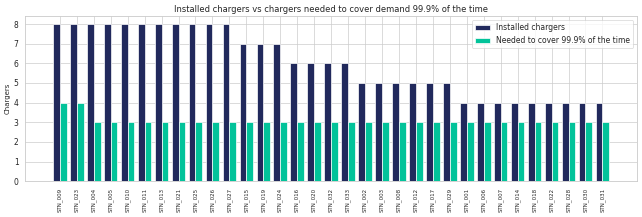

In [25]:
def chargers_needed(mins, share):
    """Smallest number of chargers that covers the station's demand for `share` of the time."""
    cum = mins.cumsum() / mins.sum()
    return int(cum[cum >= share].index.min())

need = pd.DataFrame({
    'n_chargers': n_chargers,
    'needed_99': [chargers_needed(occ[s], 0.99) for s in n_chargers.index],
    'needed_999': [chargers_needed(occ[s], 0.999) for s in n_chargers.index],
    'needed_9999': [chargers_needed(occ[s], 0.9999) for s in n_chargers.index]})
for c in ['99', '999', '9999']:
    need[f'surplus_{c}'] = need['n_chargers'] - need[f'needed_{c}']

print(need[['n_chargers', 'needed_99', 'needed_999', 'needed_9999']].sum().to_string())
print()
print(need.groupby('n_chargers')[['needed_99', 'needed_999', 'needed_9999']].mean().round(2))

x = np.arange(len(need)); w = 0.4
srt = need.sort_values(['n_chargers', 'needed_999'], ascending=False)
plt.figure(figsize=(13, 4.5))
plt.bar(np.arange(len(srt)) - w / 2, srt['n_chargers'], w, label='Installed chargers', color='#21295C')
plt.bar(np.arange(len(srt)) + w / 2, srt['needed_999'], w, label='Needed to cover 99.9% of the time', color='#02C39A')
plt.xticks(np.arange(len(srt)), srt.index, rotation=90, fontsize=8)
plt.title('Installed chargers vs chargers needed to cover demand 99.9% of the time')
plt.ylabel('Chargers'); plt.legend()
show('10_capacity_needed_vs_installed')

Across the network, 199 chargers are installed. Covering demand 99% of the time would need 70; 99.9% would need 101, and an even stricter 99.99% standard would need 127. At the 99.9% standard, almost every station needs only 3 chargers (the average is 3.00 at stations with 4-7 chargers and 3.18 at 8-charger stations), and only two stations need 4: STN_009 (Wales) and STN_023 (Scotland), both 8-charger stations. So even the busiest small stations have a spare charger, and the surplus is concentrated in larger stations.

**Saving the outputs**  
The charger-level metrics, station summary (including bottleneck and capacity measures), and the heatmap and load tables are saved as CSV files so they can be used in the dashboard.

In [26]:
ch.reset_index().to_csv(f'{OUT}/charger_metrics.csv', index=False)
station.join(need.drop(columns='n_chargers')).reset_index().to_csv(f'{OUT}/station_summary.csv', index=False)
heat_station.round(3).reset_index().to_csv(f'{OUT}/utilisation_station_by_hour.csv', index=False)
heat_network.round(3).reset_index().rename(columns={'index': 'weekday'}).to_csv(f'{OUT}/utilisation_network_weekday_hour.csv', index=False)
profile.reset_index().rename(columns={'hour': 'hour_of_day'}).to_csv(f'{OUT}/network_load_by_hour_2024.csv', index=False)
heat_charger.round(2).assign(station_id=ch['station_id'], charger_type=ch['charger_type']).reset_index().to_csv(f'{OUT}/utilisation_charger_by_hour.csv', index=False)
print(sorted(os.listdir(OUT)))

['__notebook__.ipynb', 'charger_metrics.csv', 'figures', 'network_load_by_hour_2024.csv', 'station_summary.csv', 'utilisation_charger_by_hour.csv', 'utilisation_network_weekday_hour.csv', 'utilisation_station_by_hour.csv']



1. **Do not add chargers anywhere now.** Utilisation is 5.4%; no station has any charger busy for more than 0.061% of the time, and peak load is 7.4% of installed power (10.9% in the single busiest hour of 2024).
2. **Watch the nine 4-charger stations first.** They are the only ones that approach congestion (STN_030 AND STN_022 in Lindon are at least 75% busy for about 1%of the time, with about 20% midday utilisation). If per-station demand grows, they are the first candidates for expansion. Today they still have a spare charger.
3. **Right-size the 8-charger stations.** The 11 stations with 8 chargers (88 chargers) run at 4.2% utilisation, and most need about 3 chargers to cover 99.9% of demand. For new sites, 4-5 chargers per station would match observed demand. Treat the surplus (about 98 chargers at the 99.9% standard, range 72-129) as indicative only. It assumes demand stays at about 13.9 sessions per station per day and leaves no room for maintenance or faults.
4. **Review the 300kW units before buying more.** They are 17.6% of chargers and 41% of installed power but deliver 33% of the energy, at a capacity factor of 2.6% against 6.3% for 50kW chargers. They earn more per charger per day (£75-153 vs £34-67), so the decision needs capital cost data that this dataset doesn't include.
5. **Test peak-load management.** 40.7% of energy is delivered between 10:00 and 14:59, but the peak-price window (16:00-20:59) carries 23.6%. Task 2 found no price response, so a pilot is needed before assuming that a shifted window would move demand.
6. **Fix charger allocation.** 99.8% of double-booked sessions had a free charger at the same station. Routing each session to a free charger would remove the 8.3% of overlapping sessions, and the 3,808 identical start times should be checked in the source system.
7. **Use group tiers, not individual charger rankings.** Differences between chargers of the same type and station size are noise (r = -0.09).


**Limitations**  

* The dataset appears to be simulated. Each station receives about 13.9 sessions per day regardless of its size, so station size largely determines utilisation by construction.
* The "chargers needed" estimates assume demand stays at 2022-2024 levels and cover only the 33 current stations.
* There is no fault or downtime data, so long idle spells cannot be classed as outages.
* Available time assumes each station operates from 1 January of its activation year, because installation_date is unreliable (Task 1).
* I merged overlapping sessions, so busy time excludes double-counted minutes. Load spreads each session's energy evenly over its duration and is measured at hourly resolution.
